# Proyek Analisis Data: Bike Sharing Dataset

- **Nama:** [ISI NAMA LENGKAP]
- **Email:** [ISI EMAIL YANG TERDAFTAR DI DICODING]
- **ID Dicoding:** [ISI USERNAME AKUN DICODING — BUKAN USERNAME PROGRAM MITRA/BEASISWA]

> **Wajib sebelum submission:** ganti ketiga placeholder di atas dengan identitas yang benar. ID Dicoding yang dimaksud reviewer adalah username pada akun Dicoding utama.

**Cakupan analisis:** pola penyewaan sepeda berdasarkan jam, jenis hari, musim, dan kondisi cuaca pada sistem Capital Bikeshare di Washington, D.C. selama 1 Januari 2011–31 Desember 2012.

**Petunjuk penggunaan:** simpan `day.csv` dan `hour.csv` di dalam folder `Data/` yang sejajar dengan notebook. Jalankan seluruh cell dari atas ke bawah; tahap Cleaning akan menghasilkan `Data/processed/day_clean.csv` dan `Data/processed/hour_clean.csv` untuk dashboard.

## Menentukan Pertanyaan Bisnis

Analisis diarahkan untuk mendukung keputusan operasional pengelola Capital Bikeshare, terutama penjadwalan redistribusi armada dan perencanaan kapasitas berdasarkan pola permintaan historis.

### Pertanyaan 1 — Pola permintaan per jam

**Bagaimana rata-rata jumlah penyewaan sepeda per jam (`cnt`) selama 1 Januari 2011–31 Desember 2012 di Washington, D.C. berbeda antara hari kerja dan hari bukan kerja, berapa jam puncak serta berapa rata-rata penyewaannya, sebagai dasar penentuan jadwal pemantauan stok dan redistribusi sepeda?**

- **Specific:** membandingkan profil rata-rata penyewaan untuk 24 jam antara hari kerja dan hari bukan kerja di Washington, D.C.
- **Measurable:** menghitung rata-rata `cnt` per jam, jam dengan rata-rata tertinggi, dan puncak lokal pada setiap jenis hari.
- **Action-oriented:** hasilnya digunakan untuk menentukan jam pemantauan ketersediaan serta waktu redistribusi sepeda.
- **Relevant:** ketersediaan sepeda pada jam permintaan tinggi berkaitan langsung dengan kelancaran layanan.
- **Time-bound:** periode 1 Januari 2011 sampai 31 Desember 2012.

### Pertanyaan 2 — Pola permintaan menurut musim dan cuaca

**Bagaimana rata-rata jumlah penyewaan sepeda harian (`cnt`) pada setiap kombinasi musim dan kondisi cuaca selama 1 Januari 2011–31 Desember 2012 di Washington, D.C., kombinasi mana yang tertinggi dan terendah serta berapa selisihnya, sebagai dasar penyesuaian kapasitas armada dan rencana operasional musiman?**

- **Specific:** membandingkan rata-rata penyewaan harian berdasarkan kombinasi musim dan kondisi cuaca.
- **Measurable:** menghitung rata-rata `cnt` per hari, jumlah hari pengamatan, kombinasi tertinggi/terendah, dan selisih rata-ratanya.
- **Action-oriented:** hasilnya menjadi masukan untuk menyusun skenario kapasitas armada pada kondisi musim dan cuaca yang berbeda.
- **Relevant:** musim dan cuaca merupakan konteks lingkungan yang berkaitan dengan variasi permintaan bike sharing.
- **Time-bound:** periode 1 Januari 2011 sampai 31 Desember 2012.

**Catatan metodologis:** analisis ini bersifat deskriptif. Istilah “berbeda” atau “berkaitan” digunakan dan tidak ditafsirkan sebagai bukti bahwa musim/cuaca menyebabkan perubahan penyewaan.

## Import Semua Packages/Library yang Digunakan

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## Data Wrangling

### Gathering Data

Dataset Bike Sharing terdiri dari dua file dengan tingkat agregasi berbeda:
- `day.csv`: satu baris untuk setiap tanggal.
- `hour.csv`: satu baris untuk setiap jam.

Keduanya berasal dari periode dan sistem penyewaan yang sama. Keduanya digunakan untuk analisis yang berbeda dan **tidak dijumlahkan**, agar tidak terjadi penghitungan ganda.

#### Load `day.csv` dan `hour.csv`

In [2]:
# Mendukung dua struktur: CSV di folder Data/ (struktur submission) atau langsung di folder notebook (unggahan Colab).
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Data" if (PROJECT_DIR / "Data" / "day.csv").exists() else PROJECT_DIR
DAY_PATH = DATA_DIR / "day.csv"
HOUR_PATH = DATA_DIR / "hour.csv"

if not DAY_PATH.exists() or not HOUR_PATH.exists():
    raise FileNotFoundError(
        "File day.csv dan hour.csv tidak ditemukan. Letakkan keduanya di folder Data/ "
        "atau di direktori yang sama dengan notebook. Di Google Colab, unggah kedua file "
        "melalui panel Files, atau buat folder Data/ dan simpan keduanya di sana."
    )

day_df = pd.read_csv(DAY_PATH)
hour_df = pd.read_csv(HOUR_PATH)

print(f"Lokasi data: {DATA_DIR.relative_to(PROJECT_DIR).as_posix() or '.'}")
print(f"day.csv  : {day_df.shape[0]:,} baris × {day_df.shape[1]} kolom")
print(f"hour.csv : {hour_df.shape[0]:,} baris × {hour_df.shape[1]} kolom")
print("\nContoh day.csv:")
display(day_df.head())
print("Contoh hour.csv:")
display(hour_df.head())

Lokasi data: Data
day.csv  : 731 baris × 16 kolom
hour.csv : 17,379 baris × 17 kolom

Contoh day.csv:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


Contoh hour.csv:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


**Insight Gathering Data:**
- `day.csv` berisi 731 observasi harian dan 16 kolom.
- `hour.csv` berisi 17.379 observasi per jam dan 17 kolom.
- Kedua file mencakup 1 Januari 2011 sampai 31 Desember 2012. Kolom `hr` hanya tersedia pada `hour.csv`.
- Variabel target jumlah penyewaan adalah `cnt`, yang merupakan penjumlahan pengguna kasual (`casual`) dan terdaftar (`registered`).

### Assessing Data

Pemeriksaan kualitas dilakukan terhadap kelengkapan, duplikasi, konsistensi nilai, rentang kategori, kelengkapan kombinasi tanggal–jam, serta potensi pencilan pada jumlah penyewaan.

#### 1. Memeriksa struktur, tipe data, dan format tanggal

Pemeriksaan `info()` dan `dtypes` digunakan untuk memastikan struktur DataFrame serta mengidentifikasi kolom tanggal yang masih bertipe teks. Pemeriksaan `describe()` dan rentang juga diperlukan untuk menilai variabel numerik yang dinormalisasi.

In [3]:
print("Struktur day.csv:")
day_df.info()
print("\nStruktur hour.csv:")
hour_df.info()

print("\nTipe data kolom tanggal:")
print({"day.csv": str(day_df["dteday"].dtype), "hour.csv": str(hour_df["dteday"].dtype)})

# Periksa apakah seluruh teks tanggal dapat dikonversi menjadi tanggal yang valid.
date_parse_check = pd.DataFrame({
    "Dataset": ["day.csv", "hour.csv"],
    "Tanggal tidak valid setelah parsing": [
        pd.to_datetime(day_df["dteday"], errors="coerce").isna().sum(),
        pd.to_datetime(hour_df["dteday"], errors="coerce").isna().sum()
    ]
})
display(date_parse_check)

numeric_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]
print("Ringkasan statistik variabel numerik day.csv:")
display(day_df[numeric_cols].describe().round(4))
print("Ringkasan statistik variabel numerik hour.csv:")
display(hour_df[numeric_cols].describe().round(4))

Struktur day.csv:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Struktur hour.csv:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379

,Dataset,Tanggal tidak valid setelah parsing
0,day.csv,0
1,hour.csv,0


Ringkasan statistik variabel numerik day.csv:


,temp,atemp,hum,windspeed,cnt
count,731.00,731.00,731.00,731.00,731.00
mean,0.50,0.47,0.63,0.19,"4,504.35"
std,0.18,0.16,0.14,0.08,"1,937.21"
min,0.06,0.08,0.00,0.02,22.00
25%,0.34,0.34,0.52,0.13,"3,152.00"
50%,0.50,0.49,0.63,0.18,"4,548.00"
75%,0.66,0.61,0.73,0.23,"5,956.00"
max,0.86,0.84,0.97,0.51,"8,714.00"


Ringkasan statistik variabel numerik hour.csv:


,temp,atemp,hum,windspeed,cnt
count,"17,379.00","17,379.00","17,379.00","17,379.00","17,379.00"
mean,0.50,0.48,0.63,0.19,189.46
std,0.19,0.17,0.19,0.12,181.39
min,0.02,0.00,0.00,0.00,1.00
25%,0.34,0.33,0.48,0.10,40.00
50%,0.50,0.48,0.63,0.19,142.00
75%,0.66,0.62,0.78,0.25,281.00
max,1.00,1.00,1.00,0.85,977.00


**Insight pemeriksaan struktur:** kolom `dteday` pada kedua file masih bertipe `object` (teks), sedangkan seluruh tanggal dapat dikonversi tanpa menghasilkan `NaT`. Karena tanggal dibutuhkan untuk pengelompokan waktu, kolom tersebut akan diubah menjadi `datetime` pada tahap cleaning. Variabel `temp`, `atemp`, `hum`, dan `windspeed` dinyatakan dalam skala ternormalisasi 0–1 sehingga rentang aktualnya perlu diperiksa.

#### 2. Memeriksa rentang variabel ternormalisasi dan nilai kelembapan nol

In [4]:
normalized_cols = ["temp", "atemp", "hum", "windspeed"]
range_rows = []
for dataset_name, frame in [("day.csv", day_df), ("hour.csv", hour_df)]:
    for col in normalized_cols:
        range_rows.append({
            "Dataset": dataset_name,
            "Variabel": col,
            "Minimum": frame[col].min(),
            "Maksimum": frame[col].max(),
            "Jumlah di luar [0, 1]": int((~frame[col].between(0, 1)).sum()),
            "Jumlah bernilai 0": int(frame[col].eq(0).sum())
        })
range_assessment = pd.DataFrame(range_rows)
display(range_assessment.round(4))

print("Baris day.csv dengan hum = 0:")
display(day_df.loc[day_df["hum"].eq(0), ["dteday", "season", "weathersit", "temp", "hum", "cnt"]])
print("Baris hour.csv dengan hum = 0 (ringkasan konteks):")
hum_zero_hour = hour_df.loc[hour_df["hum"].eq(0)].copy()
if not hum_zero_hour.empty:
    display(hum_zero_hour.groupby(["dteday", "season", "weathersit"], as_index=False).agg(
        jumlah_baris=("hum", "size"), jam_teramati=("hr", lambda x: ", ".join(map(str, sorted(x)))),
        total_rental_pada_baris=("cnt", "sum")
    ))
else:
    print("Tidak ada hum = 0 pada hour.csv.")

,Dataset,Variabel,Minimum,Maksimum,"Jumlah di luar [0, 1]",Jumlah bernilai 0
0,day.csv,temp,0.06,0.86,0,0
1,day.csv,atemp,0.08,0.84,0,0
2,day.csv,hum,0.00,0.97,0,1
3,day.csv,windspeed,0.02,0.51,0,0
4,hour.csv,temp,0.02,1.00,0,0
5,hour.csv,atemp,0.00,1.00,0,2
6,hour.csv,hum,0.00,1.00,0,22
7,hour.csv,windspeed,0.00,0.85,0,2180


Baris day.csv dengan hum = 0:


,dteday,season,weathersit,temp,hum,cnt
68,2011-03-10,1,3,0.39,0.00,623


Baris hour.csv dengan hum = 0 (ringkasan konteks):


,dteday,season,weathersit,jumlah_baris,jam_teramati,total_rental_pada_baris
0,2011-03-10,1,2,2,"17, 22",145
1,2011-03-10,1,3,20,"0, 1, 2, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15...",478


**Insight pemeriksaan rentang:** seluruh nilai `temp`, `atemp`, `hum`, dan `windspeed` berada pada rentang 0–1, sehingga tidak ditemukan nilai di luar rentang normalisasi. Namun, `hum = 0` ditemukan pada **1 baris day.csv** dan **22 baris hour.csv**, seluruhnya pada **10 Maret 2011**. Nilai nol tersebut mencurigakan untuk kelembapan relatif pada hari dengan kondisi cuaca berkode 3 (light rain/snow). Nilai tersebut akan ditandai sebagai tidak wajar dan diimputasi menggunakan median kelompok pembanding yang sejenis, bukan dianggap sebagai kelembapan aktual 0%.

#### 3. Memeriksa missing value dan duplicate data

In [5]:
missing_summary = pd.DataFrame({
    "day_missing": day_df.isna().sum(),
    "hour_missing": hour_df.isna().sum()
}).fillna(0).astype(int)

duplicate_summary = pd.DataFrame({
    "Dataset": ["day.csv", "hour.csv"],
    "Duplicate seluruh baris": [day_df.duplicated().sum(), hour_df.duplicated().sum()],
    "Duplicate tanggal-jam": [np.nan, hour_df.duplicated(subset=["dteday", "hr"]).sum()]
})

print("Missing value per kolom:")
display(missing_summary)
print("Pemeriksaan duplikasi:")
display(duplicate_summary)

Missing value per kolom:


,day_missing,hour_missing
atemp,0,0
casual,0,0
cnt,0,0
dteday,0,0
holiday,0,0
hr,0,0
hum,0,0
instant,0,0
mnth,0,0
registered,0,0


Pemeriksaan duplikasi:


,Dataset,Duplicate seluruh baris,Duplicate tanggal-jam
0,day.csv,0,NaN
1,hour.csv,0,0.00


#### 4. Memeriksa konsistensi dan nilai kategori

In [6]:
# Identitas jumlah penyewaan: total harus sama dengan casual + registered.
consistency_summary = pd.DataFrame({
    "Dataset": ["day.csv", "hour.csv"],
    "Mismatch cnt != casual + registered": [
        (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum(),
        (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum()
    ]
})

allowed_categories = {
    "season": {1, 2, 3, 4},
    "yr": {0, 1},
    "mnth": set(range(1, 13)),
    "holiday": {0, 1},
    "weekday": set(range(0, 7)),
    "workingday": {0, 1},
    "weathersit": {1, 2, 3, 4}
}
invalid_rows = []
for dataset_name, frame in [("day.csv", day_df), ("hour.csv", hour_df)]:
    for column, allowed in allowed_categories.items():
        invalid_count = (~frame[column].isin(allowed)).sum()
        invalid_rows.append({"Dataset": dataset_name, "Kolom": column, "Invalid value": int(invalid_count)})

print("Pemeriksaan konsistensi jumlah penyewaan:")
display(consistency_summary)
print("Pemeriksaan nilai kategori di luar kode yang diizinkan:")
display(pd.DataFrame(invalid_rows).pivot(index="Kolom", columns="Dataset", values="Invalid value"))

Pemeriksaan konsistensi jumlah penyewaan:


,Dataset,Mismatch cnt != casual + registered
0,day.csv,0
1,hour.csv,0


Pemeriksaan nilai kategori di luar kode yang diizinkan:


Dataset,day.csv,hour.csv
Kolom,,
holiday,0,0
mnth,0,0
season,0,0
weathersit,0,0
weekday,0,0
workingday,0,0
yr,0,0


#### 5. Memeriksa kelengkapan tanggal dan jam

Karena data per jam seharusnya memiliki 24 catatan untuk setiap tanggal, jumlah kombinasi tanggal–jam aktual dibandingkan dengan 24 jam yang diharapkan.

In [7]:
hour_dates = pd.to_datetime(hour_df["dteday"], errors="coerce")
unique_hours_per_date = hour_df.assign(dteday=hour_dates).groupby("dteday")["hr"].nunique()
expected_hourly_rows = hour_dates.nunique() * 24
observed_hourly_rows = len(hour_df)
incomplete_dates = unique_hours_per_date[unique_hours_per_date != 24]
complete_dates = unique_hours_per_date[unique_hours_per_date == 24].index

hour_completeness = pd.DataFrame({
    "Keterangan": [
        "Jumlah tanggal pada hour.csv",
        "Jumlah baris aktual",
        "Jumlah baris yang diharapkan (24 jam × tanggal)",
        "Kombinasi tanggal-jam yang tidak tercatat",
        "Tanggal dengan 24 jam lengkap",
        "Tanggal dengan jam tidak lengkap"
    ],
    "Nilai": [
        hour_dates.nunique(), observed_hourly_rows, expected_hourly_rows,
        expected_hourly_rows - observed_hourly_rows,
        len(complete_dates), len(incomplete_dates)
    ]
})
display(hour_completeness)

print("Distribusi jumlah jam teramati pada tanggal yang tidak lengkap:")
display(incomplete_dates.value_counts().sort_index().rename_axis("jam_teramati").reset_index(name="jumlah_tanggal"))

# Tampilkan tanggal dengan catatan paling sedikit agar konteks kekurangan rekaman terlihat.
severely_incomplete = unique_hours_per_date[unique_hours_per_date.le(18)].sort_values()
print("Tanggal dengan maksimal 18 jam tercatat:")
display(severely_incomplete.rename("jam_tercatat").reset_index().sort_values("jam_tercatat"))

,Keterangan,Nilai
0,Jumlah tanggal pada hour.csv,731
1,Jumlah baris aktual,17379
2,Jumlah baris yang diharapkan (24 jam × tanggal),17544
3,Kombinasi tanggal-jam yang tidak tercatat,165
4,Tanggal dengan 24 jam lengkap,655
5,Tanggal dengan jam tidak lengkap,76


Distribusi jumlah jam teramati pada tanggal yang tidak lengkap:


,jam_teramati,jumlah_tanggal
0,1,1
1,8,1
2,11,1
3,12,1
4,16,1
5,17,1
6,18,2
7,22,6
8,23,62


Tanggal dengan maksimal 18 jam tercatat:


,dteday,jam_tercatat
0,2012-10-29,1
1,2011-01-27,8
2,2012-10-30,11
3,2011-01-18,12
4,2011-01-26,16
5,2011-08-28,17
6,2011-02-22,18
7,2011-08-27,18


#### 6. Mengidentifikasi potential outlier dengan metode IQR

In [8]:
def iqr_outlier_summary(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data[column] < lower) | (data[column] > upper)
    return {
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "Batas bawah": lower, "Batas atas": upper,
        "Jumlah potential outlier": int(mask.sum()),
        "Persentase (%)": mask.mean() * 100
    }

outlier_summary = pd.DataFrame({
    "day.csv (cnt)": iqr_outlier_summary(day_df, "cnt"),
    "hour.csv (cnt)": iqr_outlier_summary(hour_df, "cnt")
}).T
display(outlier_summary)

# Periksa konteks semua outlier pada hour.csv, bukan hanya jumlahnya.
q1_hour_raw = hour_df["cnt"].quantile(0.25)
q3_hour_raw = hour_df["cnt"].quantile(0.75)
iqr_hour_raw = q3_hour_raw - q1_hour_raw
lower_hour_raw = q1_hour_raw - 1.5 * iqr_hour_raw
upper_hour_raw = q3_hour_raw + 1.5 * iqr_hour_raw
outlier_hour = hour_df.loc[
    (hour_df["cnt"] < lower_hour_raw) | (hour_df["cnt"] > upper_hour_raw)
].copy()
outlier_hour["season_label"] = outlier_hour["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
outlier_hour["weather_label"] = outlier_hour["weathersit"].map({
    1: "Clear", 2: "Misty / Cloudy", 3: "Light Rain / Snow", 4: "Heavy Rain / Snow"
})
outlier_hour["day_type"] = np.where(outlier_hour["workingday"].eq(1), "Working day", "Non-working day")

print("Jumlah outlier menurut jam:")
display(outlier_hour.groupby("hr").size().rename("jumlah_outlier").reset_index().sort_values("jumlah_outlier", ascending=False))
print("Jumlah outlier menurut jenis hari:")
display(outlier_hour.groupby("day_type").size().rename("jumlah_outlier").reset_index())
print("Jumlah outlier menurut musim:")
display(outlier_hour.groupby("season_label").size().rename("jumlah_outlier").reset_index())
print("Jumlah outlier menurut kondisi cuaca:")
display(outlier_hour.groupby("weather_label").size().rename("jumlah_outlier").reset_index())
print("Contoh 10 nilai outlier tertinggi beserta tanggal dan konteksnya:")
display(outlier_hour.sort_values("cnt", ascending=False)[
    ["dteday", "hr", "day_type", "season_label", "weather_label", "cnt"]
].head(10))

,Q1,Q3,IQR,Batas bawah,Batas atas,Jumlah potential outlier,Persentase (%)
day.csv (cnt),"3,152.00","5,956.00","2,804.00","-1,054.00","10,162.00",0.00,0.00
hour.csv (cnt),40.00,281.00,241.00,-321.50,642.50,505.00,2.91


Jumlah outlier menurut jam:


,hr,jumlah_outlier
7,17,153
8,18,129
0,8,127
3,13,23
2,12,17
4,14,15
9,19,14
5,15,13
6,16,12
1,11,2


Jumlah outlier menurut jenis hari:


,day_type,jumlah_outlier
0,Non-working day,91
1,Working day,414


Jumlah outlier menurut musim:


,season_label,jumlah_outlier
0,Fall,198
1,Spring,19
2,Summer,156
3,Winter,132


Jumlah outlier menurut kondisi cuaca:


,weather_label,jumlah_outlier
0,Clear,393
1,Light Rain / Snow,12
2,Misty / Cloudy,100


Contoh 10 nilai outlier tertinggi beserta tanggal dan konteksnya:


,dteday,hr,day_type,season_label,weather_label,cnt
14773,2012-09-12,18,Working day,Fall,Clear,977
14964,2012-09-20,17,Working day,Fall,Clear,976
14748,2012-09-11,17,Working day,Fall,Clear,970
14725,2012-09-10,18,Working day,Fall,Clear,968
15084,2012-09-25,17,Working day,Winter,Clear,967
15780,2012-10-24,17,Working day,Winter,Clear,963
10622,2012-03-23,17,Working day,Summer,Misty / Cloudy,957
15108,2012-09-26,17,Working day,Winter,Clear,953
15444,2012-10-10,17,Working day,Winter,Clear,948
15588,2012-10-16,17,Working day,Winter,Clear,943


### Rencana Tindakan pada Tahap Cleaning Data

Setiap tindakan berikut didasarkan pada output **Assessing Data**:

1. **Tipe data tanggal:** `dteday` bertipe `object` pada `day.csv` dan `hour.csv`, walaupun seluruh nilainya valid saat parsing. Ubah menjadi `datetime` agar dapat digunakan untuk pengelompokan dan filter waktu.
2. **Nilai kelembapan tidak wajar:** `hum = 0` ditemukan pada 1 baris harian dan 22 baris per jam, semuanya tanggal 10 Maret 2011. Karena README menyatakan `hum` adalah kelembapan ternormalisasi (persen dibagi 100), nilai nol pada catatan ini dianggap tidak wajar. Ubah nilai tersebut menjadi missing sementara, lalu imputasi dengan median kelompok pembanding: `season` dan `weathersit` untuk data harian; `season`, `weathersit`, dan `hr` untuk data per jam.
3. **Kombinasi tanggal–jam tidak lengkap:** terdapat 165 kombinasi yang tidak tercatat pada 76 tanggal; 62 tanggal memiliki 23 jam, 6 tanggal memiliki 22 jam, dan 8 tanggal memiliki paling banyak 18 jam. Jangan mengisi jam yang hilang dengan nol karena tidak ada bukti bahwa tidak terjadi penyewaan. Untuk perbandingan profil 24 jam yang adil, gunakan tanggal lengkap saja (655 tanggal).
4. **Potential outlier jumlah penyewaan per jam:** 505 baris `hour.csv` berada di atas batas IQR 642,5 (tidak ada outlier di bawah batas bawah). Outlier terkonsentrasi pada jam 17 (153 baris), 18 (129), dan 8 (127); 414 terjadi pada hari kerja dan 91 pada hari bukan kerja. Nilai tinggi juga ditemukan pada semua musim dan terutama cuaca cerah (393 baris). Karena konteksnya konsisten dengan jam permintaan tinggi dan tidak menunjukkan kesalahan input yang pasti, nilai ini **dipertahankan** serta diberi penanda `potential_outlier_cnt`; tidak dihapus otomatis.
5. **Duplikasi, missing value eksplisit, kode kategori, dan konsistensi jumlah:** tidak ditemukan duplikasi, NaN awal, kode kategori di luar daftar, atau ketidaksesuaian `cnt != casual + registered`; tidak diperlukan penghapusan atau koreksi untuk aspek tersebut.

### Cleaning Data

Pembersihan dilakukan berdasarkan hasil penilaian data. Data sumber tetap dipertahankan, sedangkan tabel bersih dibuat sebagai salinan agar keputusan pengolahan dapat ditelusuri.

#### Membersihkan format, label, dan kelengkapan data hourly

In [9]:
# Salin data sumber agar proses cleaning dapat ditelusuri tanpa mengubah DataFrame mentah.
day_clean = day_df.copy()
hour_clean_all = hour_df.copy()

# 1) Perbaiki tipe dteday dari object menjadi datetime.
day_clean["dteday"] = pd.to_datetime(day_clean["dteday"], errors="coerce")
hour_clean_all["dteday"] = pd.to_datetime(hour_clean_all["dteday"], errors="coerce")

# 2) Tangani hum = 0 yang telah ditandai tidak wajar pada tahap assessing.
# Day-level: median dari season dan weather yang sama, hanya dari nilai hum positif.
day_zero_mask = day_clean["hum"].eq(0)
day_clean.loc[day_zero_mask, "hum"] = np.nan
day_hum_median = day_clean.loc[day_clean["hum"].notna()].groupby(
    ["season", "weathersit"]
)["hum"].median()
for idx in day_clean.index[day_clean["hum"].isna()]:
    key = (day_clean.at[idx, "season"], day_clean.at[idx, "weathersit"])
    day_clean.at[idx, "hum"] = day_hum_median.loc[key]

# Hour-level: median pembanding dengan season, weather, dan jam yang sama.
hour_zero_mask = hour_clean_all["hum"].eq(0)
hour_clean_all.loc[hour_zero_mask, "hum"] = np.nan
hour_hum_median = hour_clean_all.loc[hour_clean_all["hum"].notna()].groupby(
    ["season", "weathersit", "hr"]
)["hum"].median()
for idx in hour_clean_all.index[hour_clean_all["hum"].isna()]:
    key = (
        hour_clean_all.at[idx, "season"],
        hour_clean_all.at[idx, "weathersit"],
        hour_clean_all.at[idx, "hr"]
    )
    hour_clean_all.at[idx, "hum"] = hour_hum_median.loc[key]

# Label kategori agar hasil agregasi mudah dibaca.
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {
    1: "Clear",
    2: "Misty / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

def add_readable_labels(frame):
    result = frame.copy()
    result["season_label"] = result["season"].map(season_map)
    result["weather_label"] = result["weathersit"].map(weather_map)
    result["workingday_label"] = result["workingday"].map({
        1: "Working day", 0: "Non-working day"
    })
    # day_type dipertahankan sebagai nama variabel analisis yang digunakan pada EDA.
    result["day_type"] = result["workingday_label"]
    result["year_label"] = result["yr"].map({0: 2011, 1: 2012})
    return result

day_clean = add_readable_labels(day_clean)
hour_clean_all = add_readable_labels(hour_clean_all)

# 3) Tandai potential outlier pada seluruh hour.csv dengan batas IQR dari data mentah.
q1_hour = hour_df["cnt"].quantile(0.25)
q3_hour = hour_df["cnt"].quantile(0.75)
iqr_hour = q3_hour - q1_hour
lower_hour = q1_hour - 1.5 * iqr_hour
upper_hour = q3_hour + 1.5 * iqr_hour
hour_clean_all["potential_outlier_cnt"] = (
    (hour_clean_all["cnt"] < lower_hour) | (hour_clean_all["cnt"] > upper_hour)
)

# 4) Untuk profil rata-rata 24 jam, gunakan tanggal yang memiliki 24 jam tercatat.
hours_per_day_clean = hour_clean_all.groupby("dteday")["hr"].nunique()
complete_hour_dates = hours_per_day_clean[hours_per_day_clean.eq(24)].index
hour_clean = hour_clean_all[hour_clean_all["dteday"].isin(complete_hour_dates)].copy()

print(f"day_clean       : {day_clean.shape}")
print(f"hour_clean_all  : {hour_clean_all.shape}")
print(f"hour_clean      : {hour_clean.shape} (hanya tanggal dengan 24 jam lengkap)")
print(f"Nilai hum = 0 setelah imputasi — day.csv: {int(day_clean['hum'].eq(0).sum())}; hour.csv: {int(hour_clean_all['hum'].eq(0).sum())}")
print(f"Potential outlier yang dipertahankan — seluruh hour.csv: {int(hour_clean_all['potential_outlier_cnt'].sum())}; dalam tanggal lengkap: {int(hour_clean['potential_outlier_cnt'].sum())}")
display(day_clean.head(3))
display(hour_clean.head(3))

day_clean       : (731, 21)
hour_clean_all  : (17379, 23)
hour_clean      : (15720, 23) (hanya tanggal dengan 24 jam lengkap)
Nilai hum = 0 setelah imputasi — day.csv: 0; hour.csv: 0
Potential outlier yang dipertahankan — seluruh hour.csv: 505; dalam tanggal lengkap: 502


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,workingday_label,day_type,year_label
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985,Spring,Misty / Cloudy,Non-working day,Non-working day,2011
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801,Spring,Misty / Cloudy,Non-working day,Non-working day,2011
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349,Spring,Clear,Working day,Working day,2011


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,workingday_label,day_type,year_label,potential_outlier_cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16,Spring,Clear,Non-working day,Non-working day,2011,False
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40,Spring,Clear,Non-working day,Non-working day,2011,False
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32,Spring,Clear,Non-working day,Non-working day,2011,False


In [10]:
cleaning_validation = pd.DataFrame({
    "Pemeriksaan": [
        "Tipe dteday day_clean", "Tipe dteday hour_clean_all",
        "Jumlah NaT day_clean", "Jumlah NaT hour_clean_all",
        "Jumlah hum = 0 day_clean", "Jumlah hum = 0 hour_clean_all",
        "Jumlah observasi day_clean", "Jumlah observasi hour_clean_all",
        "Jumlah observasi hour_clean (tanggal lengkap)",
        "Potential outlier pada seluruh hour_clean_all",
        "Potential outlier pada hour_clean"
    ],
    "Hasil": [
        str(day_clean["dteday"].dtype), str(hour_clean_all["dteday"].dtype),
        int(day_clean["dteday"].isna().sum()), int(hour_clean_all["dteday"].isna().sum()),
        int(day_clean["hum"].eq(0).sum()), int(hour_clean_all["hum"].eq(0).sum()),
        len(day_clean), len(hour_clean_all), len(hour_clean),
        int(hour_clean_all["potential_outlier_cnt"].sum()),
        int(hour_clean["potential_outlier_cnt"].sum())
    ]
})
display(cleaning_validation)

,Pemeriksaan,Hasil
0,Tipe dteday day_clean,datetime64[ns]
1,Tipe dteday hour_clean_all,datetime64[ns]
2,Jumlah NaT day_clean,0
3,Jumlah NaT hour_clean_all,0
4,Jumlah hum = 0 day_clean,0
5,Jumlah hum = 0 hour_clean_all,0
6,Jumlah observasi day_clean,731
7,Jumlah observasi hour_clean_all,17379
8,Jumlah observasi hour_clean (tanggal lengkap),15720
9,Potential outlier pada seluruh hour_clean_all,505


**Validasi hasil cleaning:**

- `dteday` pada `day_clean` dan `hour_clean_all` sudah bertipe `datetime64[ns]`, dan tidak menghasilkan `NaT`.
- `hum = 0` sudah tidak tersisa: 1 nilai pada `day.csv` dan 22 nilai pada `hour.csv` diimputasi dengan median kelompok pembanding.
- Data harian tetap memiliki 731 observasi; data per jam mentah tetap 17.379 observasi.
- Untuk analisis profil per jam, `hour_clean` berisi 15.720 observasi dari 655 tanggal lengkap. Rekaman dari tanggal tidak lengkap tetap tersimpan di `hour_clean_all`, tetapi tidak digunakan untuk membandingkan rata-rata per jam.
- Sebanyak 505 potential outlier dari data per jam ditandai, bukan dihapus. Hanya 502 yang berada pada 655 tanggal lengkap; tiga lainnya berada pada tanggal yang tidak lengkap.
- Tidak ada baris yang dihapus karena duplikasi atau NaN awal, sebab kedua masalah tersebut tidak ditemukan.

### Menyimpan dataset hasil preprocessing untuk dashboard

Dashboard Streamlit **tidak membaca `day.csv` dan `hour.csv` mentah secara langsung**. Dashboard menggunakan dua berkas hasil tahap *Cleaning Data* di bawah ini:

- `Data/processed/day_clean.csv`: data harian setelah konversi tanggal, imputasi nilai `hum = 0`, dan penambahan label kategori (`season_label`, `weather_label`, `workingday_label`, `day_type`, serta `year_label`).
- `Data/processed/hour_clean.csv`: data per jam setelah proses pembersihan yang sama, penandaan `potential_outlier_cnt`, dan pembatasan pada tanggal yang memiliki 24 catatan jam lengkap.

Penyimpanan ini membuat hasil preprocessing notebook menjadi sumber data yang sama untuk dashboard. Data mentah tetap dipertahankan di `Data/` untuk keterlacakan dan agar notebook dapat dijalankan ulang.


In [11]:
# Ekspor hasil cleaning sebagai sumber data dashboard.
# Folder output selalu berada di Data/processed pada direktori utama proyek.
PROCESSED_DIR = PROJECT_DIR / "Data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DAY_CLEAN_PATH = PROCESSED_DIR / "day_clean.csv"
HOUR_CLEAN_PATH = PROCESSED_DIR / "hour_clean.csv"

# dteday disimpan dalam format ISO (YYYY-MM-DD); dashboard membacanya kembali sebagai datetime.
day_clean.to_csv(DAY_CLEAN_PATH, index=False, date_format="%Y-%m-%d")
hour_clean.to_csv(HOUR_CLEAN_PATH, index=False, date_format="%Y-%m-%d")

print("Dataset hasil cleaning berhasil disimpan untuk dashboard:")
print(f"- {DAY_CLEAN_PATH.relative_to(PROJECT_DIR)} ({len(day_clean):,} baris)")
print(f"- {HOUR_CLEAN_PATH.relative_to(PROJECT_DIR)} ({len(hour_clean):,} baris; hanya tanggal dengan 24 jam lengkap)")
print("Kolom label kategori yang digunakan dashboard:")
display(day_clean[["season_label", "weather_label", "workingday_label", "day_type", "year_label"]].head())


Dataset hasil cleaning berhasil disimpan untuk dashboard:
- Data/processed/day_clean.csv (731 baris)
- Data/processed/hour_clean.csv (15,720 baris; hanya tanggal dengan 24 jam lengkap)
Kolom label kategori yang digunakan dashboard:


,season_label,weather_label,workingday_label,day_type,year_label
0,Spring,Misty / Cloudy,Non-working day,Non-working day,2011
1,Spring,Misty / Cloudy,Non-working day,Non-working day,2011
2,Spring,Clear,Working day,Working day,2011
3,Spring,Clear,Working day,Working day,2011
4,Spring,Clear,Working day,Working day,2011


## Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami distribusi dan pola penyewaan sebelum menarik kesimpulan. Analisis utama mengikuti dua pertanyaan bisnis yang telah dirumuskan.

### Eksplorasi ringkasan statistik dan komposisi pengguna

In [12]:
print("Ringkasan statistik data harian:")
display(day_clean[["casual", "registered", "cnt", "temp", "atemp", "hum", "windspeed"]].describe())

user_totals = day_clean[["casual", "registered"]].sum()
user_share = (user_totals / day_clean["cnt"].sum() * 100).rename("Persentase (%)")
user_summary = pd.concat([user_totals.rename("Total penyewaan"), user_share], axis=1)
print("Komposisi pengguna selama periode pengamatan:")
display(user_summary)

Ringkasan statistik data harian:


,casual,registered,cnt,temp,atemp,hum,windspeed
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,848.18,"3,656.17","4,504.35",0.50,0.47,0.63,0.19
std,686.62,"1,560.26","1,937.21",0.18,0.16,0.14,0.08
min,2.00,20.00,22.00,0.06,0.08,0.19,0.02
25%,315.50,"2,497.00","3,152.00",0.34,0.34,0.52,0.13
50%,713.00,"3,662.00","4,548.00",0.50,0.49,0.63,0.18
75%,"1,096.00","4,776.50","5,956.00",0.66,0.61,0.73,0.23
max,"3,410.00","6,946.00","8,714.00",0.86,0.84,0.97,0.51


Komposisi pengguna selama periode pengamatan:


,Total penyewaan,Persentase (%)
casual,620017,18.83
registered,2672662,81.17


### Eksplorasi Pertanyaan 1: rata-rata penyewaan per jam dan jenis hari

In [13]:
hourly_profile = (
    hour_clean.groupby(["day_type", "hr"], as_index=False)
    .agg(
        avg_rentals=("cnt", "mean"),
        median_rentals=("cnt", "median"),
        observations=("cnt", "size")
    )
)
hourly_pivot = hourly_profile.pivot(index="hr", columns="day_type", values="avg_rentals")

# Jam puncak global pada masing-masing jenis hari.
peak_hour = (
    hourly_profile.sort_values("avg_rentals", ascending=False)
    .groupby("day_type", as_index=False).first()
)

# Puncak lokal: rata-rata suatu jam lebih tinggi daripada jam sebelum dan sesudahnya.
local_peak_rows = []
for day_type, group in hourly_profile.groupby("day_type"):
    group = group.sort_values("hr").reset_index(drop=True)
    for pos in range(1, len(group) - 1):
        if (group.loc[pos, "avg_rentals"] > group.loc[pos - 1, "avg_rentals"]
            and group.loc[pos, "avg_rentals"] > group.loc[pos + 1, "avg_rentals"]):
            local_peak_rows.append({
                "day_type": day_type,
                "peak_hour": int(group.loc[pos, "hr"]),
                "avg_rentals": group.loc[pos, "avg_rentals"]
            })
local_peaks = pd.DataFrame(local_peak_rows)

print("Rata-rata penyewaan per jam berdasarkan jenis hari:")
display(hourly_pivot.round(1))
print("Jam puncak global untuk setiap jenis hari:")
display(peak_hour[["day_type", "hr", "avg_rentals", "observations"]].rename(columns={"hr": "peak_hour"}).round(2))
print("Seluruh puncak lokal (jam dengan rata-rata lebih tinggi daripada jam tetangganya):")
display(local_peaks.sort_values(["day_type", "peak_hour"]).round(2))

Rata-rata penyewaan per jam berdasarkan jenis hari:


day_type,Non-working day,Working day
hr,,
0,95.50,39.50
1,73.30,17.70
2,55.80,9.20
3,26.50,5.10
4,8.50,5.60
5,8.90,26.60
6,19.80,109.40
7,46.40,309.90
8,112.30,504.00


Jam puncak global untuk setiap jenis hari:


,day_type,peak_hour,avg_rentals,observations
0,Non-working day,13,390.83,212
1,Working day,17,559.66,443


Seluruh puncak lokal (jam dengan rata-rata lebih tinggi daripada jam tetangganya):


,day_type,peak_hour,avg_rentals
0,Non-working day,13,390.83
1,Working day,8,504.05
2,Working day,12,213.18
3,Working day,17,559.66


### Eksplorasi Pertanyaan 2: rata-rata penyewaan menurut musim dan cuaca

In [14]:
season_weather = (
    day_clean.groupby(["season_label", "weather_label"], observed=True)
    .agg(
        avg_rentals=("cnt", "mean"),
        median_rentals=("cnt", "median"),
        number_of_days=("cnt", "size"),
        total_rentals=("cnt", "sum")
    )
    .reset_index()
    .sort_values("avg_rentals", ascending=False)
)
print("Rata-rata penyewaan berdasarkan musim dan kondisi cuaca:")
display(season_weather.round(1))

highest_combo = season_weather.iloc[0]
lowest_combo = season_weather.iloc[-1]
avg_gap = highest_combo["avg_rentals"] - lowest_combo["avg_rentals"]
print("Kombinasi dengan rata-rata tertinggi:")
display(season_weather.head(1).round(1))
print("Kombinasi dengan rata-rata terendah:")
display(season_weather.tail(1).round(1))
print(f"Selisih rata-rata tertinggi dan terendah: {avg_gap:,.1f} penyewaan per hari")

Rata-rata penyewaan berdasarkan musim dan kondisi cuaca:


,season_label,weather_label,avg_rentals,median_rentals,number_of_days,total_rentals
0,Fall,Clear,"5,878.30","5,534.50",136,799443
6,Summer,Clear,"5,548.50","5,585.00",113,626986
2,Fall,Misty / Cloudy,"5,222.50","4,792.50",48,250679
9,Winter,Clear,"5,043.60","5,041.00",103,519487
11,Winter,Misty / Cloudy,"4,654.00","4,563.00",65,302510
8,Summer,Misty / Cloudy,"4,236.70","4,205.50",68,288096
3,Spring,Clear,"2,811.10","2,417.00",111,312036
1,Fall,Light Rain / Snow,"2,751.80","2,353.00",4,11007
5,Spring,Misty / Cloudy,"2,357.20","2,020.50",66,155573
10,Winter,Light Rain / Snow,"1,961.60","2,116.50",10,19616


Kombinasi dengan rata-rata tertinggi:


,season_label,weather_label,avg_rentals,median_rentals,number_of_days,total_rentals
0,Fall,Clear,"5,878.30","5,534.50",136,799443


Kombinasi dengan rata-rata terendah:


,season_label,weather_label,avg_rentals,median_rentals,number_of_days,total_rentals
4,Spring,Light Rain / Snow,934.80,564.50,4,3739


Selisih rata-rata tertinggi dan terendah: 4,943.5 penyewaan per hari


### Eksplorasi tambahan: tren bulanan dan hubungan variabel numerik

In [15]:
monthly_trend = (
    day_clean.assign(month_period=day_clean["dteday"].dt.to_period("M").dt.to_timestamp())
    .groupby("month_period", as_index=False)
    .agg(avg_rentals=("cnt", "mean"), total_rentals=("cnt", "sum"))
)

correlation_with_rentals = (
    day_clean[["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]]
    .corr()[["cnt"]]
    .sort_values("cnt", ascending=False)
)
print("Rata-rata dan total penyewaan per bulan selama periode penelitian:")
display(monthly_trend.round(2))
print("Bulan dengan rata-rata harian tertinggi dan terendah:")
display(pd.concat([
    monthly_trend.loc[[monthly_trend["avg_rentals"].idxmax()]],
    monthly_trend.loc[[monthly_trend["avg_rentals"].idxmin()]]
]).round(2))
print("Korelasi Pearson dengan jumlah penyewaan total (deskriptif):")
display(correlation_with_rentals.round(3))

Rata-rata dan total penyewaan per bulan selama periode penelitian:


,month_period,avg_rentals,total_rentals
0,2011-01-01,"1,231.90",38189
1,2011-02-01,"1,721.96",48215
2,2011-03-01,"2,065.97",64045
3,2011-04-01,"3,162.33",94870
4,2011-05-01,"4,381.32",135821
5,2011-06-01,"4,783.73",143512
6,2011-07-01,"4,559.39",141341
7,2011-08-01,"4,409.39",136691
8,2011-09-01,"4,247.27",127418
9,2011-10-01,"3,984.23",123511


Bulan dengan rata-rata harian tertinggi dan terendah:


,month_period,avg_rentals,total_rentals
20,2012-09-01,"7,285.77",218573
0,2011-01-01,"1,231.90",38189


Korelasi Pearson dengan jumlah penyewaan total (deskriptif):


,cnt
cnt,1.00
registered,0.95
casual,0.67
atemp,0.63
temp,0.63
hum,-0.12
windspeed,-0.23


**Insight EDA (berdasarkan hasil perhitungan):**

- Total penyewaan selama periode pengamatan adalah **3.292.679**; pengguna terdaftar menyumbang **81,17%**, sedangkan pengguna kasual **18,83%**.
- Pada **hari kerja**, terdapat **tiga puncak lokal**: pukul **08.00 (504,0 penyewaan/jam)**, pukul **12.00 (213,2 penyewaan/jam; puncak lokal yang lebih kecil)**, dan pukul **17.00 (559,7 penyewaan/jam)**. Puncak tertinggi terjadi pukul 17.00. Ringkasan dihitung dari **443 hari kerja lengkap**.
- Pada **hari bukan kerja**, terdapat **satu puncak utama**, yaitu pukul **13.00 sebesar 390,8 penyewaan/jam**, berdasarkan **212 hari bukan kerja lengkap**. Profilnya lebih terkonsentrasi pada tengah hari dibandingkan hari kerja.
- Kombinasi **Fall–Clear** memiliki rata-rata tertinggi, yaitu **5.878,3 penyewaan/hari** dari **136 hari**. Kombinasi **Spring–Light Rain / Snow** memiliki rata-rata terendah, yaitu **934,8 penyewaan/hari** dari **4 hari**. Selisihnya **4.943,5 penyewaan/hari**. Jumlah observasi terendah yang hanya empat hari perlu diperhatikan saat mengambil keputusan.
- Tabel tren bulanan menunjukkan rata-rata harian naik dari **1.231,90 penyewaan pada Januari 2011** hingga mencapai nilai tertinggi **7.285,77 pada September 2012**, kemudian turun menjadi **3.990,74 pada Desember 2012**. Ini memperlihatkan kenaikan hingga akhir musim panas 2012 dan penurunan pada akhir 2012; perubahan bulanan tidak boleh dibaca sebagai kenaikan yang selalu monoton.
- Pada data harian, korelasi Pearson dengan `cnt` bernilai positif untuk temperatur (`temp` sekitar **0,63**) dan temperatur terasa (`atemp` sekitar **0,63**), serta negatif untuk kecepatan angin (`windspeed` sekitar **-0,23**). Korelasi ini bersifat deskriptif dan tidak membuktikan sebab-akibat.

## Visualization & Explanatory Analysis

Visualisasi berikut dirancang untuk menjawab masing-masing pertanyaan bisnis. Label, judul, dan satuan disertakan agar grafik dapat dipahami tanpa penjelasan lisan.

### Pertanyaan 1 — Bagaimana rata-rata jumlah penyewaan sepeda per jam (`cnt`) selama 1 Januari 2011–31 Desember 2012 di Washington, D.C. berbeda antara hari kerja dan hari bukan kerja, berapa jam puncak serta berapa rata-rata penyewaannya, sebagai dasar penentuan jadwal pemantauan stok dan redistribusi sepeda?

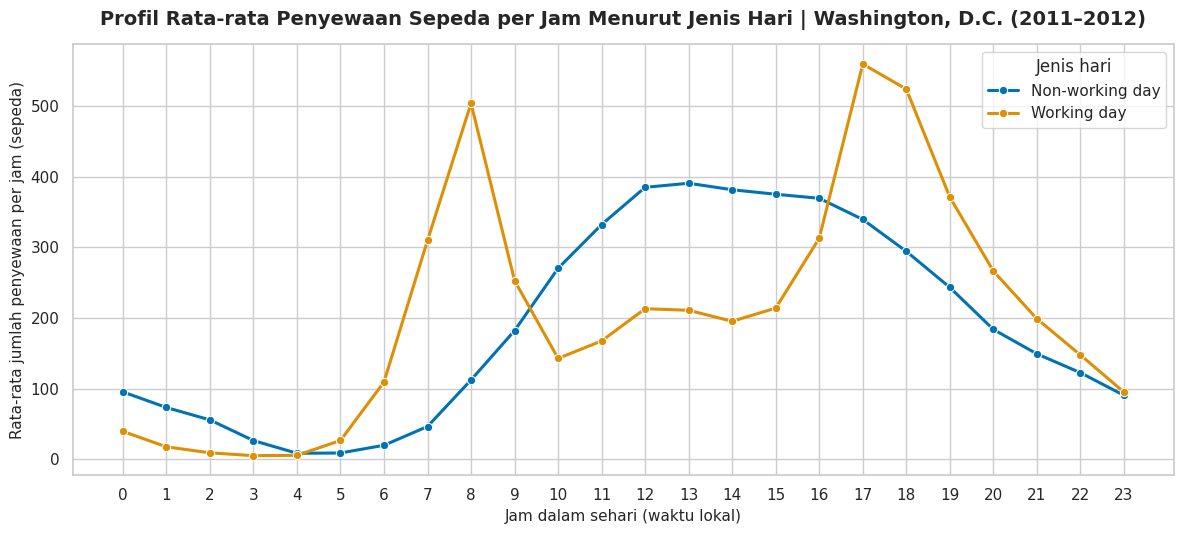

In [16]:
plt.figure(figsize=(12, 5.5))
sns.lineplot(
    data=hourly_profile,
    x="hr", y="avg_rentals", hue="day_type",
    marker="o", linewidth=2.2
)
plt.title("Profil Rata-rata Penyewaan Sepeda per Jam Menurut Jenis Hari | Washington, D.C. (2011–2012)", pad=14, weight="bold")
plt.xlabel("Jam dalam sehari (waktu lokal)")
plt.ylabel("Rata-rata jumlah penyewaan per jam (sepeda)")
plt.xticks(range(24))
plt.legend(title="Jenis hari", frameon=True)
plt.tight_layout()
plt.show()

**Explanatory insight — Pertanyaan 1:**

Garis hari kerja memperlihatkan **tiga puncak lokal**, yaitu pukul **08.00 sebesar 504,0 penyewaan/jam**, pukul **12.00 sebesar 213,2 penyewaan/jam** (tonjolan yang relatif kecil), dan pukul **17.00 sebesar 559,7 penyewaan/jam**. Puncak global hari kerja terjadi pada pukul **17.00**, dengan rata-rata tertinggi sebesar **559,7 penyewaan/jam**. Pola pagi dan sore menunjukkan dua periode utama yang perlu diperhatikan dalam penempatan armada. Perhitungan memakai **443 tanggal kerja lengkap**.

Garis hari bukan kerja memiliki **satu puncak lokal utama**, yakni pukul **13.00 sebesar 390,8 penyewaan/jam**, dihitung dari **212 tanggal bukan kerja lengkap**. Permintaan hari bukan kerja lebih menyebar di sekitar siang hari, bukan membentuk dua puncak komuter pagi–sore seperti hari kerja. Dengan demikian, hasil grafik menjawab jam puncak kedua jenis hari sekaligus memberi dasar waktu pemantauan stok: sebelum pukul 08.00 dan 17.00 pada hari kerja, serta sebelum pukul 13.00 pada hari bukan kerja.

Grafik menggambarkan rata-rata historis Capital Bikeshare di Washington, D.C. pada 1 Januari 2011–31 Desember 2012, bukan jaminan pola yang sama pada periode saat ini.

### Pertanyaan 2 — Bagaimana rata-rata jumlah penyewaan sepeda harian (`cnt`) pada setiap kombinasi musim dan kondisi cuaca selama 1 Januari 2011–31 Desember 2012 di Washington, D.C., kombinasi mana yang tertinggi dan terendah serta berapa selisihnya, sebagai dasar penyesuaian kapasitas armada dan rencana operasional musiman?

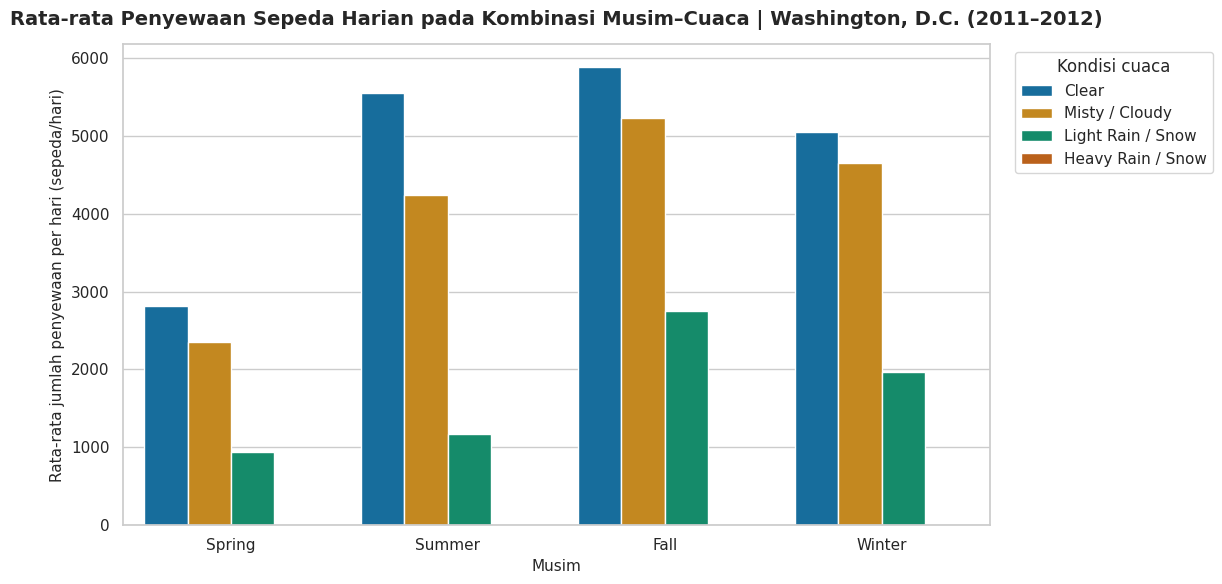

In [17]:
season_order = ["Spring", "Summer", "Fall", "Winter"]
weather_order = ["Clear", "Misty / Cloudy", "Light Rain / Snow", "Heavy Rain / Snow"]

plt.figure(figsize=(12, 6))
sns.barplot(
    data=season_weather,
    x="season_label", y="avg_rentals", hue="weather_label",
    order=season_order, hue_order=weather_order,
    errorbar=None
)
plt.title("Rata-rata Penyewaan Sepeda Harian pada Kombinasi Musim–Cuaca | Washington, D.C. (2011–2012)", pad=14, weight="bold")
plt.xlabel("Musim")
plt.ylabel("Rata-rata jumlah penyewaan per hari (sepeda/hari)")
plt.legend(title="Kondisi cuaca", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Explanatory insight — Pertanyaan 2:**

Kombinasi musim dan kondisi cuaca dengan rata-rata penyewaan harian **tertinggi** adalah **Fall–Clear**, yaitu **5.878,3 penyewaan per hari** dari **136 hari pengamatan**. Kombinasi dengan rata-rata **terendah** adalah **Spring–Light Rain / Snow**, yaitu **934,8 penyewaan per hari** dari **4 hari pengamatan**. Selisih kedua rata-rata tersebut adalah **4.943,5 penyewaan per hari**.

Artinya, dalam data 2011–2012, kondisi Fall dengan cuaca cerah berasosiasi dengan volume penyewaan rata-rata paling tinggi, sedangkan kombinasi Spring dengan hujan ringan/salju memiliki rata-rata paling rendah. Namun, kelompok terendah hanya terdiri atas empat hari; hasilnya tidak boleh diperlakukan sebagai estimasi stabil untuk semua hari musim semi berhujan. Perbedaan ini bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat. Untuk perencanaan, pengelola dapat memakai Fall–Clear sebagai skenario permintaan tinggi, sambil memantau data aktual dan tidak mengurangi armada secara berlebihan berdasarkan kelompok empat hari.

## Analisis Lanjutan (Opsional): Binning Tingkat Permintaan

Analisis lanjutan menggunakan teknik **binning** untuk mengelompokkan hari berdasarkan jumlah penyewaan. Batas kategori ditentukan dari sebaran `cnt` pada data harian (tercile/kuantil), bukan dengan algoritma machine learning. Tujuannya adalah menyederhanakan pemantauan tingkat permintaan.

In [18]:
demand_bins = day_clean.copy()
demand_bins["demand_level"] = pd.qcut(
    demand_bins["cnt"],
    q=3,
    labels=["Low demand", "Medium demand", "High demand"]
)

demand_by_season = (
    demand_bins.groupby(["season_label", "demand_level"], observed=False)
    .size()
    .rename("number_of_days")
    .reset_index()
)
demand_by_season["percentage_within_season"] = (
    demand_by_season["number_of_days"] /
    demand_by_season.groupby("season_label")["number_of_days"].transform("sum") * 100
)

display(demand_by_season.round(1))

,season_label,demand_level,number_of_days,percentage_within_season
0,Fall,Low demand,13,6.90
1,Fall,Medium demand,79,42.00
2,Fall,High demand,96,51.10
3,Spring,Low demand,140,77.30
4,Spring,Medium demand,33,18.20
5,Spring,High demand,8,4.40
6,Summer,Low demand,37,20.10
7,Summer,Medium demand,71,38.60
8,Summer,High demand,76,41.30
9,Winter,Low demand,54,30.30


**Insight analisis lanjutan:**

Hasil binning menunjukkan distribusi tingkat permintaan berbeda antar-musim. Pada **Spring**, hari dengan **Low demand mendominasi sebesar 77,3%** (140 hari), sedangkan High demand hanya 4,4% (8 hari). Pada **Fall**, **High demand mendominasi sebesar 51,1%** (96 hari), sementara Low demand hanya 6,9% (13 hari). Pada **Winter**, distribusi relatif merata: **30,3% Low**, **34,3% Medium**, dan **35,4% High demand**. Pada Summer, kategori High demand mencakup 41,3% hari.

Informasi ini dapat dipakai sebagai ringkasan historis untuk menyusun skenario kapasitas: siapkan kapasitas lebih tinggi pada periode Fall, sedangkan Spring lebih sering berada pada kategori permintaan rendah. Kategori dibuat dengan `qcut` (tercile) berdasarkan distribusi keseluruhan 731 hari, sehingga batas Low/Medium/High bersifat relatif terhadap dataset Washington, D.C. tahun 2011–2012 dan perlu dihitung ulang untuk periode atau kota lain.

## Conclusion & Recommendation

### Kesimpulan

1. **Pertanyaan 1 — Pola penyewaan per jam:** selama periode 1 Januari 2011–31 Desember 2012 di Washington, D.C., hari kerja memiliki **tiga puncak lokal**, yaitu pukul **08.00 (504,0 penyewaan/jam)**, pukul **12.00 (213,2 penyewaan/jam; puncak lokal kecil)**, dan pukul **17.00 (559,7 penyewaan/jam)**. Puncak tertinggi hari kerja terjadi pukul 17.00. Pada hari bukan kerja terdapat **satu puncak utama**, yaitu pukul **13.00 (390,8 penyewaan/jam)**. Perhitungan menggunakan **443 hari kerja** dan **212 hari bukan kerja** yang masing-masing memiliki 24 catatan jam lengkap. Jadi, pola hari kerja lebih menyerupai dua periode permintaan utama (pagi dan sore), sedangkan hari bukan kerja lebih terkonsentrasi pada tengah hari.

2. **Pertanyaan 2 — Musim dan cuaca:** rata-rata penyewaan harian tertinggi ditemukan pada kombinasi **Fall–Clear**, sebesar **5.878,3 penyewaan/hari** dari **136 hari**. Rata-rata terendah ditemukan pada **Spring–Light Rain / Snow**, sebesar **934,8 penyewaan/hari** dari **4 hari**. Selisih rata-ratanya sebesar **4.943,5 penyewaan/hari**. Karena kelompok terendah hanya memiliki empat observasi, hasil tersebut perlu ditafsirkan hati-hati dan tidak cukup menjadi dasar tunggal untuk mengurangi kapasitas armada.

### Rekomendasi Action Item

1. **Atur jadwal pemantauan dan redistribusi pada hari kerja:** lakukan pemeriksaan ketersediaan sebelum pukul **08.00** dan **17.00**, dengan prioritas lebih tinggi menjelang pukul 17.00 karena rata-rata historis mencapai **559,7 penyewaan/jam** dibandingkan **504,0 penyewaan/jam** pada pukul 08.00.
2. **Sesuaikan operasi hari bukan kerja:** jadwalkan pemeriksaan dan pengisian ulang armada sebelum pukul **13.00**, saat rata-rata historis mencapai **390,8 penyewaan/jam**.
3. **Gunakan Fall–Clear sebagai skenario kapasitas tinggi:** rata-rata historis **5.878,3 penyewaan/hari dari 136 hari** dapat menjadi acuan awal untuk menguji kecukupan armada pada periode permintaan tinggi. Pantau kapasitas dan tingkat ketersediaan secara berkala.
4. **Jangan membuat pengurangan armada permanen hanya dari Spring–Light Rain / Snow:** rata-rata **934,8 penyewaan/hari** didasarkan pada empat hari saja. Kumpulkan lebih banyak observasi dan evaluasi kondisi aktual sebelum menetapkan kapasitas minimum.
5. **Perbarui perencanaan dengan data terbaru:** pola ini berasal dari Washington, D.C. tahun 2011–2012. Validasi kembali jam puncak dan profil musim/cuaca menggunakan data operasional terkini sebelum diterapkan.

> Seluruh rekomendasi merupakan implikasi operasional dari analisis deskriptif, bukan kesimpulan kausal.

## Referensi Dataset

Fanaee-T, H., & Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge*. **Progress in Artificial Intelligence**. https://doi.org/10.1007/s13748-013-0040-3

Deskripsi dataset menyebutkan bahwa data berasal dari Capital Bikeshare, Washington, D.C., dengan agregasi harian dan per jam serta informasi cuaca dan musim.